# Лабораторная работа №3. Анализ сетевого трафика

## Часть 2. Таксономия сетевых атак

## Выполнили работу:
### Симахин Степан Андреевич ИНБс-5301-01-00
### Игнатович Вадим Олегович ИНБс-5301-01-00

---

Часть 2: используется полная выборка (файл `KDDTrain+` для обучения и файл `KDDTest+` для тестирования), при этом решается не бинарная задача, а задача мультиклассовой классификации, – необходимо определять атаки и разделять их по классам.

## Шаг 0. Подключение датасета

Подключение архива с файлами датасета происходит посредством монтирования файла в Google Drive:

In [107]:
# функция для нормального вывода списков:
def to_str(inp, sep=', '):
  #return str(inp)[1:-1]
  return sep.join(str(it) for it in inp)

# подключение архива datasets.zip, который лежит в Google Диск:
#   прямая ссылка на datasets.zip:
#   https://drive.google.com/file/d/1pt9PgKb9ckkTVfx5YhvzmhfOCREtySsk/view?usp=sharing
from google.colab import drive
drive.mount('/content/drive')
!unzip -q "/content/drive/MyDrive/datasets.zip" -d /content/
print('Файл \'datasets.zip\' подключён')

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).
replace /content/datasets/ids.csv? [y]es, [n]o, [A]ll, [N]one, [r]ename: Файл 'datasets.zip' подключён


Подключение файлов в архиве датасета:

In [109]:
import os

# Где лежат данные: рядом с блокнотом (локально) или в /content (Colab)
# DATA_DIR = 'datasets' if os.path.isdir('datasets') else '/content/datasets'
DATA_DIR = 'datasets'

for name in ['ids.csv', 'KDDTrain+.csv', 'KDDTest+.csv']:
    path = os.path.join(DATA_DIR, name)
    assert os.path.isfile(path), (
        f'Файл {name} не найден по пути {path}. '
        'В Colab выполните ячейку «Шаг 0», локально — положите папку datasets рядом с блокнотом.')

print('Успешно найденные файлы датасета: {}.'.format(to_str(sorted(os.listdir(DATA_DIR)))))

Успешно найденные файлы датасета: KDDTest+.csv, KDDTrain+.csv, ids.csv.


Подключение библиотек:

In [110]:
import time

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.model_selection import train_test_split, GridSearchCV
from sklearn.preprocessing import OrdinalEncoder, MinMaxScaler
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import make_pipeline

from sklearn.naive_bayes import GaussianNB
from sklearn.tree import DecisionTreeClassifier
from sklearn.neighbors import KNeighborsClassifier
from sklearn.linear_model import LogisticRegression

from sklearn.metrics import (accuracy_score, precision_score, recall_score,
                             f1_score, classification_report,
                             ConfusionMatrixDisplay)
from matplotlib.colors import LinearSegmentedColormap

print('Библиотеки подключены')

# what is that below?
RANDOM_STATE = 2  # фиксируем, чтобы результаты воспроизводились

Библиотеки подключены


## Шаг 1. Загрузка KDDTrain+

Используется полный датасет, разделённый на файлы:
* файл `DDTrain+.csv` — подмножество для обучения (125973 записи);
* файл `KDDTest+.csv` — подмножество для тестирования (22543 записи).

Предпоследняя колонка файлов называется *label* и принимает следующие значения метки:
* нормальный трафик: normal;
* DoS-атаки: neptune, smurf, back, etc.;
* пробирование (разведка): nmap, ipsweep, portsweep, satan, etc.;
* R2L-атаки (Remote-to-Local): warezclient, etc.;
* U2R-атаки (User-to-Root): buffer_overflow, rootkit, loadmodule, perl, etc.

Из приведённых атак наиболее тяжело определимы атаки групп R2L и U2R, так как такие атаки схожи с обычным поведением пользователя, при этом атак этих групп в датасете обучения меньше всего.

Последняя колонка файлов называется *difficulty* и означает количество машин (систем обнаружения атак), которые смогли верно категоризировать запись (из 21 машин), т.е. чем меньше значение, тем сложнее определить класс записи. Данный показатель опускается при анализе и обучении.
<br><br>
В данных файлах нет заголовка с перечислением параметров, поэтому они задаются вручную:

In [112]:
COLS = ['duration', 'protocol_type', 'service', 'flag', 'src_bytes', 'dst_bytes',
        'land', 'wrong_fragment', 'urgent', 'hot', 'num_failed_logins', 'logged_in',
        'num_compromised', 'root_shell', 'su_attempted', 'num_root', 'num_file_creations',
        'num_shells', 'num_access_files', 'num_outbound_cmds', 'is_host_login',
        'is_guest_login', 'count', 'srv_count', 'serror_rate', 'srv_serror_rate',
        'rerror_rate', 'srv_rerror_rate', 'same_srv_rate', 'diff_srv_rate',
        'srv_diff_host_rate', 'dst_host_count', 'dst_host_srv_count',
        'dst_host_same_srv_rate', 'dst_host_diff_srv_rate', 'dst_host_same_src_port_rate',
        'dst_host_srv_diff_host_rate', 'dst_host_serror_rate', 'dst_host_srv_serror_rate',
        'dst_host_rerror_rate', 'dst_host_srv_rerror_rate', 'label', 'difficulty']

data = pd.read_csv(os.path.join(DATA_DIR, 'KDDTrain+.csv'), header=None, names=COLS)
print('Размеры файла \'KDDTrain+\':', data.shape)
print('\nПервые строки файла:')
data.head(5)

Размеры файла 'KDDTrain+': (125973, 43)

Первые строки файла:


,duration,protocol_type,service,flag,src_bytes,dst_bytes,land,wrong_fragment,urgent,hot,...,dst_host_same_srv_rate,dst_host_diff_srv_rate,dst_host_same_src_port_rate,dst_host_srv_diff_host_rate,dst_host_serror_rate,dst_host_srv_serror_rate,dst_host_rerror_rate,dst_host_srv_rerror_rate,label,difficulty
0,0,tcp,ftp_data,SF,491,0,0,0,0,0,...,0.17,0.03,0.17,0.00,0.00,0.00,0.05,0.00,normal,20
1,0,udp,other,SF,146,0,0,0,0,0,...,0.00,0.60,0.88,0.00,0.00,0.00,0.00,0.00,normal,15
2,0,tcp,private,S0,0,0,0,0,0,0,...,0.10,0.05,0.00,0.00,1.00,1.00,0.00,0.00,neptune,19
3,0,tcp,http,SF,232,8153,0,0,0,0,...,1.00,0.00,0.03,0.04,0.03,0.01,0.00,0.01,normal,21
4,0,tcp,http,SF,199,420,0,0,0,0,...,1.00,0.00,0.00,0.00,0.00,0.00,0.00,0.00,normal,21


Распределение меток (нормального трафика и трафика атак) в файла `KDDTrain+`:

In [113]:
print('Различных меток:', data['label'].nunique())
print('\nСтатистика по метрикам:')
print(data['label'].value_counts().to_string())

Различных меток: 23

Статистика по метрикам:
label
normal             67343
neptune            41214
satan               3633
ipsweep             3599
portsweep           2931
smurf               2646
nmap                1493
back                 956
teardrop             892
warezclient          890
pod                  201
guess_passwd          53
buffer_overflow       30
warezmaster           20
land                  18
imap                  11
rootkit               10
loadmodule             9
ftp_write              8
multihop               7
phf                    4
perl                   3
spy                    2


Распределение классов файла `KDDTrain+` в виде графика столбчатых диаграмм:

Text(0, 0.5, 'Число записей')

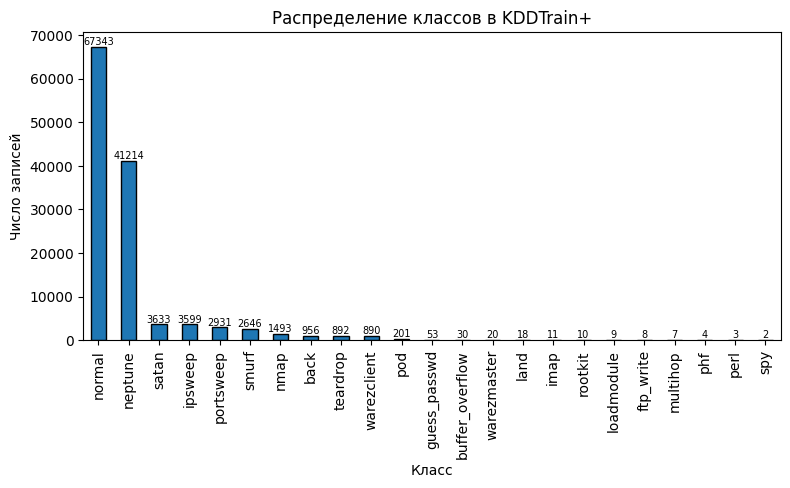

In [114]:
gr = data['label'].value_counts().plot(kind='bar', figsize=(9, 4), edgecolor='black', title='Распределение классов в KDDTrain+')
gr.set_xlabel('Класс')
gr.bar_label(gr.containers[0], fmt='{:.0f}', fontsize=7)
gr.set_ylabel('Число записей')

## Шаг 2. Таксономия: 22 типа атак → 4 категории

Для предотвращения переобучения и для упрощения обучения метки классифицированы на 5 классов в соответствии с ранее определёнными классами атак:
* нормальный трафик: normal;
* DoS-атаки: neptune, smurf, back, etc.;
* пробирование (разведка): nmap, ipsweep, portsweep, satan, etc.;
* R2L-атаки (Remote-to-Local): warezclient, etc.;
* U2R-атаки (User-to-Root): buffer_overflow, rootkit, loadmodule, perl, etc.
<br>
Для реализации данной классификации используется блок кода ниже, который учитывает вхождения из файла `KDDTest+`:

In [116]:
ATTACK_CATEGORY = {
    # normal:
    'normal': 'normal',
    # DoS:
    'neptune': 'dos', 'smurf': 'dos', 'back': 'dos', 'teardrop': 'dos',
    'pod': 'dos', 'land': 'dos', 'apache2': 'dos', 'udpstorm': 'dos',
    'processtable': 'dos', 'mailbomb': 'dos', 'worm': 'dos',
    # probing:
    'satan': 'probe', 'ipsweep': 'probe', 'portsweep': 'probe',
    'nmap': 'probe', 'mscan': 'probe', 'saint': 'probe',
    # R2L (remote to local):
    'warezclient': 'r2l', 'guess_passwd': 'r2l', 'warezmaster': 'r2l',
    'imap': 'r2l', 'ftp_write': 'r2l', 'multihop': 'r2l', 'phf': 'r2l',
    'spy': 'r2l', 'httptunnel': 'r2l', 'snmpguess': 'r2l',
    'snmpgetattack': 'r2l', 'named': 'r2l', 'sendmail': 'r2l',
    'xlock': 'r2l', 'xsnoop': 'r2l',
    # U2R (user to root):
    'buffer_overflow': 'u2r', 'rootkit': 'u2r', 'loadmodule': 'u2r',
    'perl': 'u2r', 'ps': 'u2r', 'sqlattack': 'u2r', 'xterm': 'u2r',
}

data['category'] = data['label'].map(ATTACK_CATEGORY)
assert data['category'].notna().all(), 'Найдены метки вне словаря'

cat_counts = data['category'].value_counts()
print('Статистика трафика файла \'KDDTrain+\' по категориям:')
print(cat_counts.to_string())
print('\nРаспределение категорий:\n' + '\n'.join(f'{k}     \t{v / len(data):.2%}' for k, v in cat_counts.items()))

Статистика трафика файла 'KDDTrain+' по категориям:
category
normal    67343
dos       45927
probe     11656
r2l         995
u2r          52

Распределение категорий:
normal     	53.46%
dos     	36.46%
probe     	9.25%
r2l     	0.79%
u2r     	0.04%


Распределение полученных классов в виде столбчатой диаграммы:

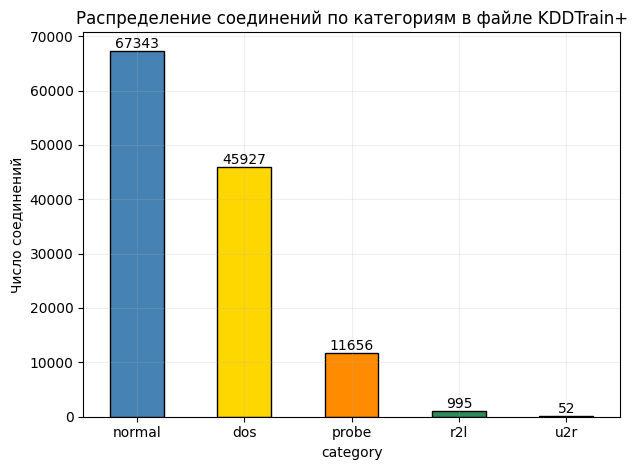

In [117]:
colors = ['steelblue', 'gold', 'darkorange', 'seagreen', 'indianred']
ax = cat_counts.plot.bar(color=colors, edgecolor='black')
ax.bar_label(ax.containers[0], fmt='{:.0f}', fontsize=10)

plt.title('Распределение соединений по категориям в файле KDDTrain+')
plt.ylabel('Число соединений')
plt.xticks(rotation=0)
plt.grid(alpha=0.2)
plt.tight_layout()
plt.show()

Вопросы:
1. Во сколько примерно раз записей `dos` больше, чем `u2r`?
2. Что это означает для recall класса `u2r`?

Ответы:
1. Записи категории DoS относятся к записям категории U2R как 1295 к 1.
2. Характеристика `recall` означает долю TP от всех истинно P (чем выше, тем больше атак отлавливается). Для категории U2R значение этой характеристики ожидается ниже, чем для категории DoS, так как доля трафика с атаками U2R крайне мало.

## Шаг 3. Предобработка

Для нормальной работы алгоритмов классификации необходимо закодировать не численные параметры (категориальные признаки) и нормализовать численные параметры до отрезка [0,1].

Параметр `difficulty` (последний столбец) отбрасывается, так как в анализе и обучении не участвует.

Добавление флага `handle_unknown='use_encoded_value'` обязательно, так как в файле `KDDTrain+` есть 70 значений параметра `service`, поэтому после разбиения файла на датасеты для обучения и тестирования часть этих значений может оказаться только в одном из датасетов. Данный флаг принуждает повторно кодировать не численные параметры в численный вид.
<br><br>
Реализация предобработки:

In [119]:
X = data.drop(columns=['label', 'difficulty', 'category'])
y = data['category']

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=RANDOM_STATE, stratify=y)

cat_cols = ['protocol_type', 'service', 'flag']
num_cols = [c for c in X.columns if c not in cat_cols]

preprocess = ColumnTransformer([
    ('cat', OrdinalEncoder(handle_unknown='use_encoded_value', unknown_value=-1), cat_cols),
    ('num', MinMaxScaler(), num_cols),
])

print('Статистика записей в полученных датасетах:')
print(f'- соединений в train:\t{X_train.shape[0]}\n- соединений в test:\t{X_test.shape[0]}')
print('\nКатегории в train: ' + to_str(y_train.value_counts().to_dict()))
print('Категории в test:  ' + to_str(y_test.value_counts().to_dict()))

Статистика записей в полученных датасетах:
- соединений в train:	100778
- соединений в test:	25195

Категории в train: normal, dos, probe, r2l, u2r
Категории в test:  normal, dos, probe, r2l, u2r


## Шаг 4. k-NN классификатор

Для работы данного алгоритма необходимо определить число соседей k:
* слишком малое значение – риск переобучения;
* слишком большое значение – размытая граница решений, подавление редких классов;
* значение кратное числу классов – риск систематического появления ничьих при голосовании;
* чётное значение – риск систематического появления ничьих при голосовании.
<br>
Выбор числа соседей k посредством кросс-валидации:


In [120]:
# WARNING: takes 3 minutes to run
k_list = [1, 3, 5]

grid_knn = GridSearchCV(
    make_pipeline(preprocess, KNeighborsClassifier(n_jobs=-1)),
    {'kneighborsclassifier__n_neighbors': k_list},
    cv=5, n_jobs=-1, scoring='accuracy')

t0 = time.time()
grid_knn.fit(X_train, y_train)
print(f'Время расчёта всех моделей: {time.time() - t0:.1f} с')
print(f'Параметры лучшей модели:\n\t- \'k\' = {grid_knn.best_params_.get('kneighborsclassifier__n_neighbors')}.')
print(f'Значение accuracy на кросс-валидации: {grid_knn.best_score_:.4f}')

model_knn = grid_knn.best_estimator_
y_pred = model_knn.predict(X_test)
print(f'Значение accuracy на датасете для тестирования: {accuracy_score(y_test, y_pred):.3f}')

Время расчёта всех моделей: 200.7 с
Параметры лучшей модели:
	- 'k' = 1.
Значение accuracy на кросс-валидации: 0.9964
Значение accuracy на датасете для тестирования: 0.996


В итоге было получено оптимальное значение количества соседей: **k = 1**

График сравнения моделей при разных значениях данного параметра:

Сравнение моделей при разном количестве соседей:



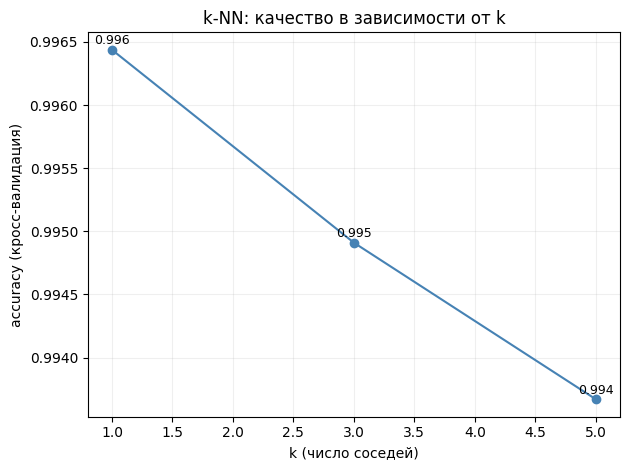

In [138]:
neighbors = [p['kneighborsclassifier__n_neighbors'] for p in grid_knn.cv_results_['params']]
scores = grid_knn.cv_results_['mean_test_score']
plt.plot(neighbors, scores, marker='o', color='steelblue')
for x, y in zip(neighbors, scores):
    plt.annotate(f'{y:.3f}', (x, y), textcoords='offset points', xytext=(0, 4), ha='center', fontsize=9)

plt.xlabel('k (число соседей)')
plt.ylabel('accuracy (кросс-валидация)')
plt.title('k-NN: качество в зависимости от k')
plt.grid(alpha=0.2)
plt.tight_layout()
print('Сравнение моделей при разном количестве соседей:\n')
plt.show()

Результат моделирования по алгоритму k-NN:

In [122]:
k = 1     # число соседей k

model_knn = make_pipeline(preprocess, KNeighborsClassifier(n_neighbors=k, n_jobs=-1))

t0 = time.time()
model_knn.fit(X_train, y_train)
t1 = time.time()
y_pred = model_knn.predict(X_test)
t2 = time.time()

print(f'Число соседей k = {k}')
print(f'\nВремя обучения: {t1 - t0:.1f} с\nВремя прогнозирования при {len(X_test)} соединений: {t2 - t1:.1f} с')
print(f'Полученное значение accuracy: {accuracy_score(y_test, y_pred):.3f}')
print('\nПолученные характеристики:\n')
print(classification_report(y_test, y_pred, digits=3, zero_division=0))

Число соседей k = 1

Время обучения: 0.5 с
Время прогнозирования при 25195 соединений: 21.2 с
Полученное значение accuracy: 0.996

Полученные характеристики:

              precision    recall  f1-score   support

         dos      0.998     0.999     0.998      9186
      normal      0.997     0.997     0.997     13469
       probe      0.992     0.991     0.992      2331
         r2l      0.953     0.920     0.936       199
         u2r      0.500     0.500     0.500        10

    accuracy                          0.996     25195
   macro avg      0.888     0.881     0.885     25195
weighted avg      0.996     0.996     0.996     25195



Результаты моделирования и прогнозирования:
* время обучения крайне мало, так как обучение заключается в структурированном сохранении всего заданного датасета;
* время прогнозирования крайне велика, так как процесс получения результата заключается в обработке всей сохранённой матрице, полученной по датасету, в котором находится 10^5 значений;
* полученная accuracy снова выше 99%, что подтверждает ранее полученные выводы:  датасеты содержат искусственно созданный баланс нормального и аномального трафика, в итоге модели легко повторяют результат, полученный при обучении; датасеты являются лабораторными, баланс классов изначально ненормален и позволяет моделям успешно повторять результат; приоритет FP над FN: при использовании полученных моделей будет формироваться недопустимо много ложных срабатываний;
* для классов категории U2R значение accuracy оказалось равно 50%, так как в датасете было крайне мало таких записей.

Получение матрицы ошибок при использовании алгоритма k-NN:

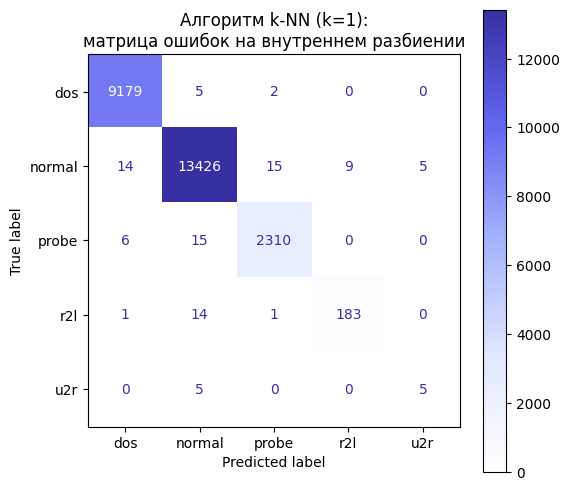

In [123]:
#custom_cmap = LinearSegmentedColormap.from_list(".", ["white", "blue"])
color_list = ["#ffffff", "#e0e7ff", "#a5b4fc", "#6366f1", "#3730a3"]
custom_cmap = LinearSegmentedColormap.from_list("myblue", color_list)
fig, ax = plt.subplots(figsize=(6, 6))
ConfusionMatrixDisplay.from_predictions(y_test, y_pred, ax=ax, cmap=custom_cmap)
plt.title(f'Алгоритм k-NN (k={k}):\nматрица ошибок на внутреннем разбиении')
plt.show()

Вопросы:
1. Означают ли 99 %, что классификатор готов к обработке реального трафика?

Ответы:
1. Как было отмечено, accuracy > 99% означает, что модель достаточно точно повторяет работу на другой части того же искусственного датасете. С учётом крайне малого числа записей в датасете для U2R (10 записей) и R2L (199 записей), как и ожидалось ранее, количестве ошибок достаточно велико, так как данный алгоритм не способен равнозначно обрабатывать классы, примеры которых в датасете много, и классы, пример которых крайне мало.

## Шаг 5. Решающее дерево для сравнения

Для определения значения параметра `max_depth` таким же образом ищется оптимальное значение данного параметра.

При запуске перебора гиперпараметров с оценкой качества по `accuracy` график после `max_depth` > 10 вышел на монотонно возрастающее плато, в итоге по полученным значениям лучшим значением оказалось `max_depth` = None, то есть лучшим деревом оказалось неограниченное, что нарушает прошлые выводы.

Для решения данной проблемы оценка качества стала производиться по параметру `scoring='neg_log_loss'` – оценка в виде штрафов, а не точности; значения отрицательны, при этом чем значение ближе к нулю, тем меньше штраф, что означает более высокую точность оценки системой; чем дальше значение от нуля, тем больше штраф, который система получает за большое число ошибочных оценок.
<br><br>
Реализация перебора гиперпараметров по параметру `scoring='neg_log_loss'`:

In [124]:
# WARNING: takes 1 minute to run

max_depth_list = [2, 3, 4, 5, 6, 7, 8, 9, 10, 15, 20, None]

grid_tree = GridSearchCV(
    make_pipeline(preprocess, DecisionTreeClassifier(random_state=RANDOM_STATE)),
    {'decisiontreeclassifier__max_depth': max_depth_list},
    cv=5, n_jobs=-1, scoring='neg_log_loss')

t0 = time.time()
grid_tree.fit(X_train, y_train)
print(f'Размер сетки для GridSearchCV = {len(max_depth_list)}')
print(f'Число отбираемых моделей равно 1x{len(max_depth_list)}={1*len(max_depth_list)}')
print(f'Время моделирования всех моделей: {time.time() - t0:.1f} с')
print(f'Параметры лучшей модели:\n\t- \'max_depth\' = {grid_tree.best_params_.get('decisiontreeclassifier__max_depth')}.')
print(f'Accuracy на кросс-валидации: {grid_tree.best_score_:.4f}')

Размер сетки для GridSearchCV = 12
Число отбираемых моделей равно 1x12=12
Время моделирования всех моделей: 56.8 с
Параметры лучшей модели:
	- 'max_depth' = 8.
Accuracy на кросс-валидации: -0.0529


В итоге лучшим значением оказалось равно `'max_depth'` = 8, а не None, а значит, проблема была решена.

Получение графика сравнения моделей при разных значениях параметра:

Используется модель со значением 'max_depth' = 8

Полученное значение ошибки на датасете тестирования: 0.993
Полученные характеристики:

              precision    recall  f1-score   support

         dos      0.996     0.999     0.998      9186
      normal      0.994     0.995     0.994     13469
       probe      0.979     0.976     0.977      2331
         r2l      0.924     0.789     0.851       199
         u2r      0.333     0.100     0.154        10

    accuracy                          0.993     25195
   macro avg      0.845     0.772     0.795     25195
weighted avg      0.992     0.993     0.992     25195


Получаемое значение ошибки при разных значениях параметра 'max_depth':



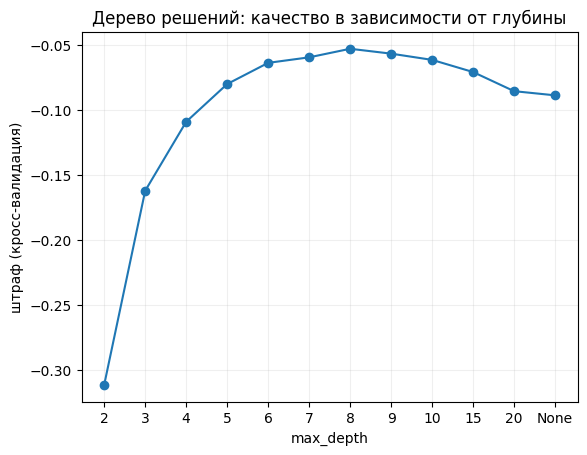

In [125]:
print(f'Используется модель со значением \'max_depth\' = {grid_tree.best_params_.get('decisiontreeclassifier__max_depth')}')
model_tree = grid_tree.best_estimator_
y_pred = model_tree.predict(X_test)

print(f'\nПолученное значение ошибки на датасете тестирования: {accuracy_score(y_test, y_pred):.3f}')
print('Полученные характеристики:\n')
print(classification_report(y_test, y_pred, digits=3))

depths = [str(p['decisiontreeclassifier__max_depth']) for p in grid_tree.cv_results_['params']]
scores = grid_tree.cv_results_['mean_test_score']

print('\nПолучаемое значение ошибки при разных значениях параметра \'max_depth\':\n')
plt.plot(range(len(depths)), scores, marker='o')
plt.xticks(range(len(depths)), depths)
plt.xlabel('max_depth')
plt.ylabel('штраф (кросс-валидация)')
plt.title('Дерево решений: качество в зависимости от глубины')
plt.grid(alpha=0.2)
plt.show()

## Шаг 6. Честная проверка: тестовый набор KDDTest+

Для честной проверки для обучения и тестирования используются разные, специально для этого разделённые датасеты, а не один и тот же сет, поэтому при тестировании будут встречаться не только записи с новыми значениями поля `service`, но и записи с новыми типами атак:

In [131]:
test_data = pd.read_csv(os.path.join(DATA_DIR, 'KDDTest+.csv'), header=None, names=COLS)
train_data_demo = pd.read_csv(os.path.join(DATA_DIR, 'KDDTrain+.csv'), header=None, names=COLS)
test_data['category'] = test_data['label'].map(ATTACK_CATEGORY)
train_data_demo['category'] = train_data_demo['label'].map(ATTACK_CATEGORY)
assert test_data['category'].notna().all()

new_attacks = sorted(set(test_data['label']) - set(data['label']))
print(f'Всего типов меток в \'KDDTest+\': {test_data["label"].nunique()}\nНовых меток (нет в \'KDDTrain+\'): {len(new_attacks)}')
print('Список новых типов меток: ' + ', '.join(new_attacks))
print('\nСтатистика категорий в \'KDDTrain+\':')
print(train_data_demo['category'].value_counts().to_string())
print('\nСтатистика категорий в \'KDDTest+\':')
print(test_data['category'].value_counts().to_string())

print('\nРаспределение категорий в \'KDDTrain+\':')
for cat, share in train_data_demo['category'].value_counts(normalize=True).items():
  print(f'{cat}:\t{share*100 :.2f}%')
print('\nРаспределение категорий в \'KDDTest+\':')
for cat, share in test_data['category'].value_counts(normalize=True).items():
  print(f'{cat}:\t{share*100 :.2f}%')

Всего типов меток в 'KDDTest+': 38
Новых меток (нет в 'KDDTrain+'): 17
Список новых типов меток: apache2, httptunnel, mailbomb, mscan, named, processtable, ps, saint, sendmail, snmpgetattack, snmpguess, sqlattack, udpstorm, worm, xlock, xsnoop, xterm

Статистика категорий в 'KDDTrain+':
category
normal    67343
dos       45927
probe     11656
r2l         995
u2r          52

Статистика категорий в 'KDDTest+':
category
normal    9710
dos       7460
r2l       2885
probe     2421
u2r         67

Распределение категорий в 'KDDTrain+':
normal:	53.46%
dos:	36.46%
probe:	9.25%
r2l:	0.79%
u2r:	0.04%

Распределение категорий в 'KDDTest+':
normal:	43.07%
dos:	33.09%
r2l:	12.80%
probe:	10.74%
u2r:	0.30%


! Добавить про распределение

In [134]:
# Переобучаем обе модели на ВСЁМ тренировочном наборе и проверяем на KDDTest+
# WARNING: takes 0.5 minute to run
y = data['category']
X_full, y_full = X, y
X_test_real, y_test_real = (test_data.drop(columns=['label', 'difficulty', 'category']),
                            test_data['category'])

models = [(f'k-NN (k={k})',  lambda: KNeighborsClassifier(n_neighbors=k, n_jobs=-1)),
          ('Дерево решений', lambda: DecisionTreeClassifier(random_state=RANDOM_STATE))]
models_real = {}
for name, make_model in models:
    model = make_pipeline(preprocess, make_model())
    t0 = time.time()
    model.fit(X_full, y_full)
    acc = model.score(X_test_real, y_test_real)
    models_real[name] = model
    print(f'Время обучение модели \'{name}\': {time.time() - t0:.1f} с\nЗначение accuracy на KDDTest+: {acc:.3f}\n')

Время обучение модели 'k-NN (k=1)': 25.0 с
Значение accuracy на KDDTest+: 0.751

Время обучение модели 'Дерево решений': 2.1 с
Значение accuracy на KDDTest+: 0.769



это очень страно (время)

In [135]:
# Подробный отчёт для лучшей модели (дерево решений)
y_pred_real = models_real['Дерево решений'].predict(X_test_real)
print(classification_report(y_test_real, y_pred_real, digits=3, zero_division=0))

              precision    recall  f1-score   support

         dos      0.954     0.828     0.886      7460
      normal      0.700     0.966     0.811      9710
       probe      0.642     0.634     0.638      2421
         r2l      0.941     0.083     0.152      2885
         u2r      0.571     0.179     0.273        67

    accuracy                          0.769     22543
   macro avg      0.762     0.538     0.552     22543
weighted avg      0.808     0.769     0.732     22543



! ниже переписать

Сравните accuracy на внутреннем разбиении (~99 %) и на KDDTest+ (~78 %). Куда «пропали» 20 процентных пунктов? Посмотрите на recall классов `r2l` и `u2r`: что с ними стало и почему?

Объяснение (сверьтесь с вашими предположениями):

- В тестовом наборе **новые типы атак** (mscan, apache2, snmpguess и др.) — их соединения классификатор никогда не видел и относит к похожим знакомым классам, часто к `normal`.
- **Распределения категорий сдвинуты**: в тесте доля `r2l` заметно выше, чем в train, а это самая трудная категория (её признаки похожи на нормальный трафик — например, `guess_passwd` внешне выглядит как обычные попытки входа).
- Внутреннее разбиение измеряет «узнала ли модель знакомые атаки», а честный протокол — «заметит ли она незнакомые». Это разные вопросы, и для IDS важнее второй.

! оформить выводы ниже

## Выводы по части 2

Сформулируйте прямо в этой ячейке:

1. Чем задача этой части отличается от задачи части 1 и почему 23 метки пришлось свести к 5 категориям?
2. Какие классы распознаются хуже всего на честном тесте и почему?
3. Что показал протокол «KDDTrain+ → KDDTest+» по сравнению с внутренним разбиением? Какой вывод для практики оценки ML-моделей в безопасности?

**Вопросы (необязательные):**

- Почему для категорий `r2l` и `u2r` полнота низкая даже при высокой общей accuracy? Какой приём из ЛР № 2 помог бы сдвинуть баланс в пользу редких классов (подсказка: `class_weight`)?
- В тестовом наборе атаки `worm` всего 2 записи. Что покажет для такого класса `classification_report` и насколько этим цифрам можно верить?
- Предложите способ улучшить обнаружение *незнакомых* атак, не перечисленных в обучающей выборке. (Подсказка: вспомните про обучение без учителя и выявление аномалий — методичка, Приложение А.)